# Staffing Boston's 311 City Service Teams

IE 5374 Applied Generative AI, Module 7 Hackathon, Topic 2.

We plan how many field crews four City of Boston departments need in each month of 2025, using the
real 311 requests from 2023 and 2024, and we build a 311 intake assistant that turns a resident's
message into the right request type, department and queue.

| Code | Department |
|---|---|
| PWDx | Public Works |
| BTDT | Transportation |
| PARK | Parks and Recreation |
| ISD | Inspectional Services |

The request data is real. Crew capacities, costs and starting crews are the planning assumptions
from the brief, all read from `config.yaml`.

**AI use.** We used AI tools while building this project; every use is listed in
`docs/ai_use_log.md`. Sections whose content was generated by an LLM are marked *AI-generated*.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import data, forecast, equity

%matplotlib inline
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

## 1. Data

Both years come straight from the raw CSV files in `data/raw/`. The files are large (about 175 MB
each), so we read them with DuckDB and keep only the four departments before doing anything else.
Timestamps stay in local Boston time. 2025 data is not used, because the city changed 311 systems
in October 2025.

In [2]:
con = data.duckdb.connect()
raw = data.load_requests(con)
data.counts_by_year(raw).pivot(index="department", columns="year", values="requests")

year,2023,2024
department,,
BTDT,75314,81447
ISD,18123,18624
PARK,17541,18736
PWDx,171268,157610


### Check against the brief

The 2024 request counts and on-time shares should match the brief: 157,610 / 81,447 / 18,736 /
18,624 requests and 90% / 50% / 93% / 72% on time.

In [3]:
check = data.check_2024(raw)
check["brief_requests"] = check.department.map({"PWDx": 157610, "BTDT": 81447, "PARK": 18736, "ISD": 18624})
check["brief_on_time_pct"] = check.department.map({"PWDx": 90, "BTDT": 50, "PARK": 93, "ISD": 72})
check

,department,requests,on_time_pct,on_time_pct_with_target,no_target,brief_requests,brief_on_time_pct
0,BTDT,81447,49.9,48.9,1600,81447,50
1,ISD,18624,72.4,72.3,67,18624,72
2,PARK,18736,93.2,93.0,415,18736,93
3,PWDx,157610,89.7,87.3,29339,157610,90


Counts match exactly, and the on-time shares match when **every** request is counted. Requests
with no target date are all marked ONTIME in the data; leaving them out would drop Public Works to
87%, so we count all requests the same way the brief does.

### Cleaned file

`requests_clean.parquet` holds one row per request with the team's column names, plus helper
columns `year, month, has_target, days_to_close, source_group`. Every request is counted as
workload, whatever its closure reason. `case_title` has HTML codes decoded and whitespace trimmed.

In [4]:
if not data.CLEAN_FILE.exists():
    data.build_clean_file()
df = data.load_clean()
print(f"{len(df):,} rows, {df.shape[1]} columns")
df.isna().sum().rename("missing").to_frame().T

558,663 rows, 16 columns


,id,opened,target,closed,department,type,queue,case_title,neighborhood,source,on_time,year,month,has_target,days_to_close,source_group
missing,0,0,82143,51814,0,0,0,0,4046,0,0,0,0,0,51814,2


In [5]:
no_target = (~df.has_target).groupby(df.year).mean().mul(100).round(1)
print("Share of requests with no target date (%):")
no_target

Share of requests with no target date (%):


year
2023    18.0
2024    11.4
Name: has_target, dtype: float64

About 11% of 2024 requests in our four departments have no target date (16% across every
department in the file, which is the brief's figure). Many Parks requests have a 365-day target,
and 42% of all requests were logged by city employees rather than residents (Section 6 looks at
this).

## 2. Forecast

### Monthly demand, 2023-2024

In [6]:
demand = forecast.monthly_demand(df)
demand.pivot_table(index="month", columns=["department", "year"], values="requests")

department    BTDT             ISD            PARK             PWDx         
year          2023    2024    2023    2024    2023    2024     2023     2024
month                                                                       
1           5692.0  5620.0  1307.0  1491.0   765.0   928.0  12843.0  13582.0
2           5316.0  5954.0  1793.0  1285.0   651.0   794.0   9978.0  11550.0
3           6889.0  7209.0  1240.0  1342.0   911.0  1291.0  12402.0  13092.0
4           6143.0  7008.0  1201.0  1415.0  1206.0  1519.0  12985.0  13998.0
5           6737.0  7511.0  1386.0  1555.0  2095.0  2029.0  15267.0  13333.0
6           6682.0  7176.0  1723.0  1779.0  2313.0  2881.0  14947.0  12917.0
7           5517.0  6678.0  1587.0  1796.0  2299.0  2640.0  16188.0  13915.0
8           6473.0  6719.0  1723.0  2077.0  2382.0  2143.0  20224.0  16398.0
9           7190.0  7633.0  1678.0  1809.0  1532.0  1587.0  18578.0  15912.0
10          7018.0  7675.0  1597.0  1610.0  1366.0  1153.0  14113.0  11639.0
11          5964.0  6606.0  1537.0  1215.0   810.0   935.0  11813.0  10172.0
12          5693.0  5658.0  1351.0  1250.0  1211.0   836.0  11930.0  11102.0

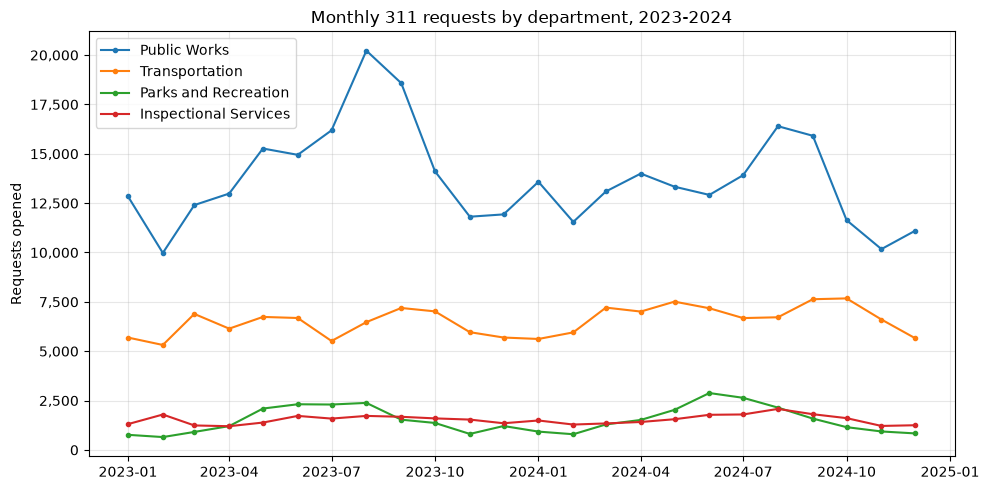

In [7]:
forecast.plot_monthly_demand(demand);

Public Works peaks in August-September, and Parks more than triples from January to June, as the
brief describes. Public Works also fell about 8% from 2023 to 2024, while the other three
departments grew 3-8%.

### 2025 forecast

With only 24 monthly points per department, a fitted time-series model would not be reliable, so we
use a simple seasonal method:

- **seasonal share** = each month's share of its year's requests, averaged over 2023 and 2024
- **2025 annual total** = 2024 total x (2024 total / 2023 total), carrying the 2023-to-2024 growth
  rate one more year
- **forecast** = seasonal share x 2025 annual total

There are no low/high ranges here; the +/-20% demand scenarios in the sensitivity section cover
uncertainty.

In [8]:
fc = forecast.forecast_2025(demand)
table = fc.pivot(index="month", columns="department", values="forecast")[data.DEPTS]
table.loc["Total"] = table.sum()
table

department,PWDx,BTDT,PARK,ISD
month,,,,
1,11688,6367,932,1456
2,9539,6328,795,1607
3,11275,7926,1209,1344
4,11939,7381,1499,1361
5,12599,8001,2279,1531
6,12273,7787,2858,1824
7,13257,6837,2721,1761
8,16109,7418,2503,1977
9,15188,8332,1721,1816


In [9]:
totals = forecast.annual_totals(demand)
totals["growth_%"] = ((totals[2024] / totals[2023] - 1) * 100).round(1)
totals["forecast_2025"] = fc.groupby("department").forecast.sum()
totals.loc[data.DEPTS]

year,2023,2024,growth_%,forecast_2025
department,,,,
PWDx,171268,157610,-8.0,145040
BTDT,75314,81447,8.1,88078
PARK,17541,18736,6.8,20010
ISD,18123,18624,2.8,19140


**Checking the method.** We forecast 2024 from 2023 alone (2023's monthly pattern at 2023's total)
and compare with what actually happened. MAPE is the average monthly error.

In [10]:
forecast.backtest_2024(demand)

,department,MAPE %
0,PWDx,13.6
1,BTDT,7.6
2,PARK,17.7
3,ISD,13.3


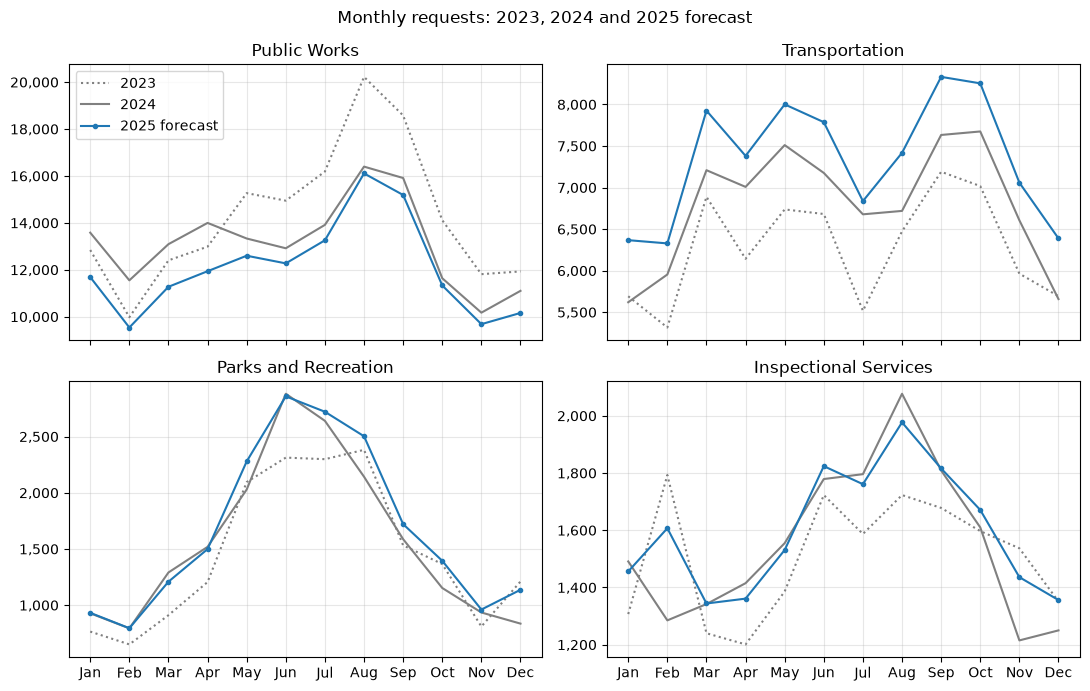

In [11]:
forecast.plot_forecast(demand, fc);

Transportation is the most predictable (about 8% error). Parks has the largest error because its
2024 peak came in June instead of August. The Public Works error is mostly the 8% drop in its
annual total, which a one-year backtest cannot see. The 2025 forecast carries that drop forward,
so Public Works is the forecast to watch most closely.

## 3. Intake Assistant

*Person B (Kavin): `src/catalog.py`, `src/intake.py`, `app/`.*

A resident describes a problem in their own words. The assistant finds the request type, the
department and the queue, and asks one follow-up question when the message is unclear. It
combines three course techniques: **embeddings + retrieval (RAG)**, **prompt engineering**
(zero-shot vs few-shot) and **structured output** (a Pydantic schema as the response format).

Every LLM and embedding call is cached in `data/cache/`, so this section makes **no API calls**
and gives the same result every run.

### Request-type catalog

158 request types handled by the four departments in 2024. Department and queue come from the
data; the one-sentence descriptions are **AI-generated** by `gpt-4o-mini` (temperature 0) and
reviewed by the team. Example titles are taken from the real `case_title` values; in this file
the title is usually just the type name, so most types have only one.

In [12]:
from src import intake

catalog = intake.load_catalog()
cat = pd.DataFrame(catalog)
print(f"{len(cat)} request types:", cat.department.value_counts().to_dict())
cat[["type", "department", "n_2024", "primary_queue", "description"]].head(10)

158 request types: {'PWDx': 62, 'ISD': 62, 'BTDT': 22, 'PARK': 12}


,type,department,n_2024,primary_queue,description
0,Parking Enforcement,BTDT,63064,BTDT_Parking Enforcement,"Cars are parked in no-parking zones, blocking ..."
1,Requests for Street Cleaning,PWDx,20564,PWDx_District 1C: Downtown,"My street is dirty with trash, leaves, or debr..."
2,Improper Storage of Trash (Barrels),PWDx,20340,PWDx_Code Enforcement,Trash barrels are left out on the sidewalk or ...
3,CE Collection,PWDx,18011,PWDx_District 1C: Downtown,The street needs to be cleaned because there i...
4,Schedule a Bulk Item Pickup,PWDx,11828,PWDx_Schedule a Bulk Item Pickup,I need to schedule a pickup for large items li...
5,Missed Trash/Recycling/Yard Waste/Bulk Item,PWDx,10588,PWDx_Missed Trash\Recycling\Yard Waste\Bulk Item,"My trash, recycling, yard waste, or bulk items..."
6,Poor Conditions of Property,PWDx,8706,PWDx_Code Enforcement,"The property has overgrown weeds, trash, or ot..."
7,Mattress_Pickup,PWDx,8533,PWDx_WM_Mattress_Pickup,I need to get rid of an old mattress that’s ta...
8,Tree Maintenance Requests,PARK,8355,PARK_Tree Maintenance Request,"Branches are hanging too low, a tree is damage..."
9,Request for Pothole Repair,PWDx,8029,PWDx_Roadway Repair_ARP_Resurfacing,My street has a big pothole that’s damaging ca...


### Test set

44 resident-style messages written before any model run (`data/test_messages.csv`): 39 clear
(17 PWDx, 10 BTDT, 6 PARK, 6 ISD, two of them with two problems) and 5 deliberately unclear,
where the right answer is a follow-up question. `acceptable_types` lists near-identical types
that also count as correct (e.g. the two bulk-item pickup types).

In [13]:
test = pd.read_csv(ROOT / "data/test_messages.csv")
test[["id", "message", "true_type", "true_department", "is_ambiguous"]].sample(6, random_state=1)

,id,message,true_type,true_department,is_ambiguous
3,T04,moving out saturday and need to get rid of a m...,Mattress_Pickup,PWDx,False
2,T03,"got an old couch and a dresser i need gone, ca...",Schedule a Bulk Item Pickup,PWDx,False
30,T31,can the city plant a tree in front of my house...,New Tree Requests,PARK,False
21,T22,we need a crosswalk painted outside the elemen...,New Sign Crosswalk or Pavement Marking,BTDT,False
22,T23,theres a bike chained to the rack on newbury f...,Abandoned Bicycle,BTDT,False
41,T42,something smells awful outside my building,NaN,NaN,True


### Retrieval (embeddings)

Each type is embedded as *name + description + example titles* with `text-embedding-3-small`;
each message is embedded the same way and the types are ranked by cosine similarity. The top 8
become the LLM's candidates, so the true type must be among them (target: recall@8 ≥ 95%).

In [14]:
ret = intake.evaluate_retrieval()
pd.DataFrame({f"recall@{k}": [(ret.rank_true <= k).mean()] for k in (1, 3, 5, 8)},
             index=["true type in top k"]).style.format("{:.0%}")

,recall@1,recall@3,recall@5,recall@8
true type in top k,56%,85%,97%,100%


### Structured output and three prompt versions

The LLM (`gpt-4o-mini`, temperature 0) returns an `IntakeResult`: request type, 2 alternatives,
confidence, whether a follow-up is needed, and the question. **The LLM only picks the type;
department and queue are looked up from the catalog in code**, so it cannot invent either. If
the type is not one of the candidates, the call is retried once and then flagged.

| Version | What the model sees |
|---|---|
| V1 | all 158 type names, no examples (zero-shot) |
| V2 | V1 + 6 worked examples (none from the test set) |
| V3 | the top-8 retrieved types with descriptions + the same 6 examples |

In [15]:
res, summary = intake.evaluate_versions()
summary.drop(columns="flagged").style.format({c: "{:.0%}" for c in summary.columns[1:-1]})

,description,department_acc,type_top1,type_top3,queue_acc,asks_on_unclear,quiet_on_clear
version,,,,,,,
V1,"zero-shot, all type names",97%,85%,90%,79%,20%,100%
V2,V1 + 6 worked examples,97%,90%,92%,82%,80%,100%
V3,top-8 retrieved types (with descriptions) + 6 worked examples,95%,90%,100%,77%,100%,97%


V1 → V2: the worked examples mostly teach *behaviour* — asking a follow-up on unclear messages
rises from 20% to 80%. V3 puts the right type in the top 3 for every clear message and asks on
all 5 unclear ones, so the app uses V3. Queue accuracy is lower because many types are routed to
a district queue that depends on the address.

### Error analysis

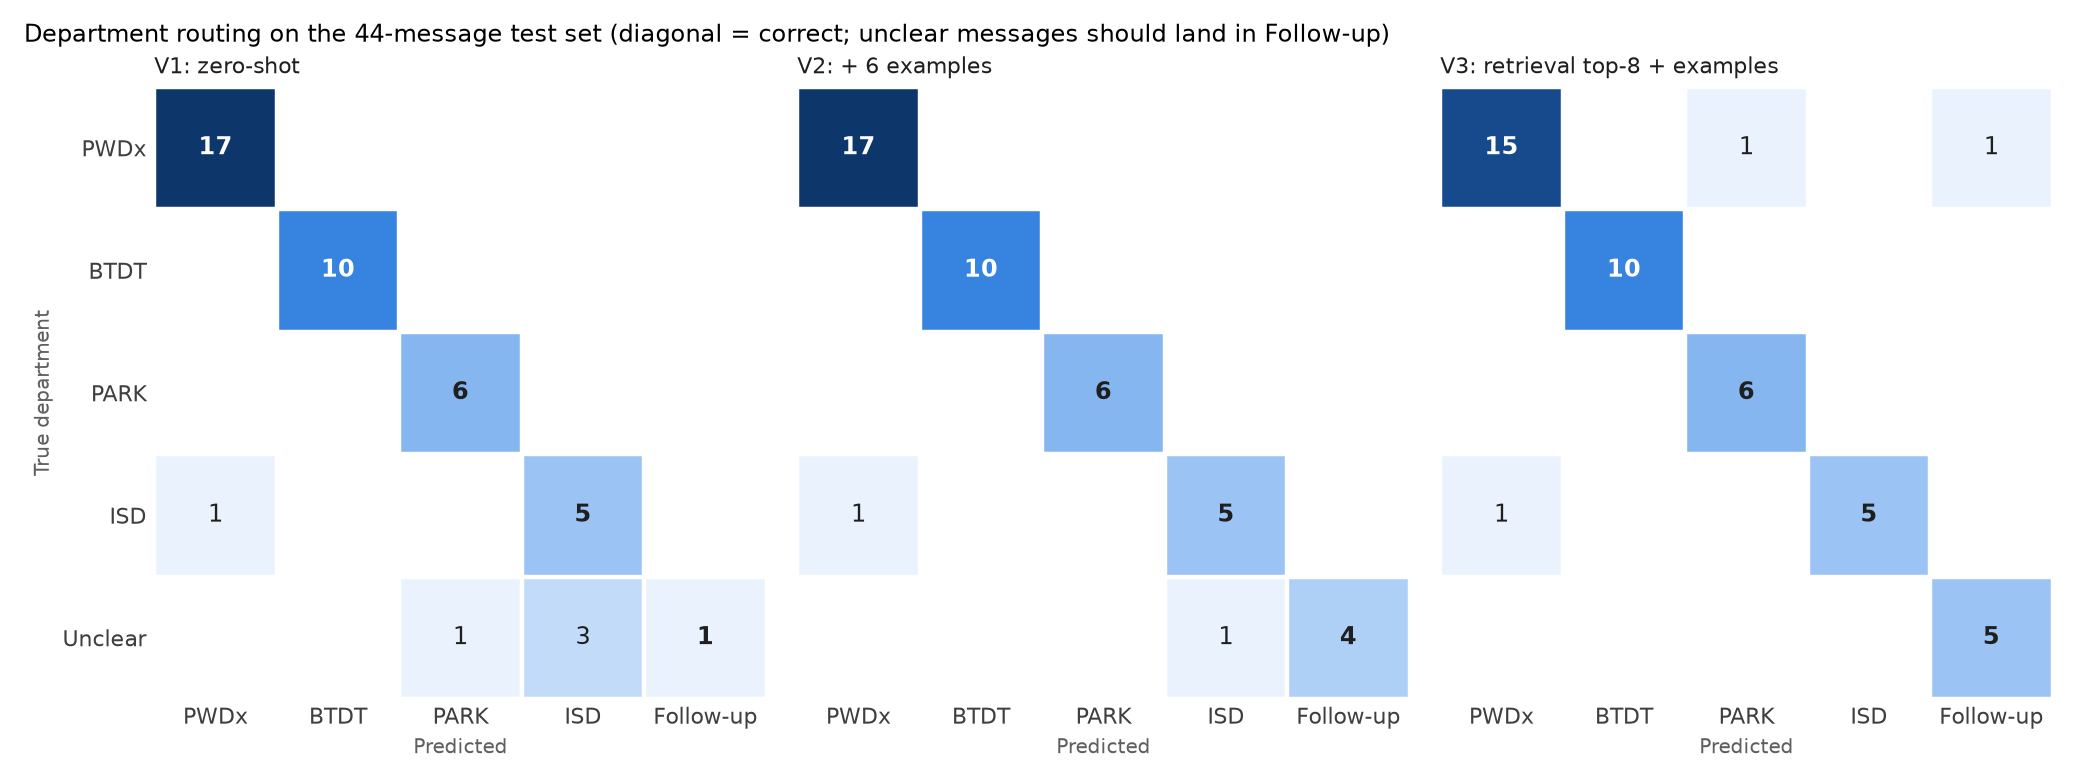

In [16]:
intake.plot_confusion(res)
display(Image(str(intake.FIG_PATH)))

In [17]:
v3 = res[(res.version == "V3") & ~res.is_ambiguous & ~res.type_top1]
v3[["id", "message", "true_type", "pred_type", "pred_department", "alternatives"]]

,id,message,true_type,pred_type,pred_department,alternatives
91,T04,moving out saturday and need to get rid of a m...,Mattress_Pickup,Schedule a Bulk Item Pickup,PWDx,Mattress_Pickup|Schedule a Bulk Item Pickup SS
101,T14,tons of spray paint tags all over the underpas...,PWD Graffiti,Graffiti Removal,PARK,PWD Graffiti|Traffic Signal Repair
105,T18,somebody parked across my driveway on tremont ...,Parking Enforcement,Valet Parking Problems,BTDT,Parking Enforcement|Private Parking Lot Compla...
125,T38,construction site next door starts banging at ...,Working Beyond Hours,Work Hours-Loud Noise Complaints,PWDx,Working Beyond Hours|Exceeding Terms of Permit


*AI-drafted, reviewed by the team.* V3's wrong types are near-synonyms. Three of the four trace
back to the AI-written catalog descriptions rather than to the intake prompt: "Valet Parking
Problems" (7 requests in 2024) beat "Parking Enforcement" (63,064) because its description
mentions a blocked driveway, and PARK's rare "Graffiti Removal" beat PWDx's "PWD Graffiti". The
fix belongs in the catalog (human review of descriptions, or showing each type's request count).
Limits: 44 test messages is small, and the same AI wrote the test messages and the descriptions,
so real-world accuracy is probably lower. Details: `docs/intake_error_analysis.md`.

### Example

The same pipeline the Streamlit app uses (`streamlit run app/app.py`):

In [18]:
assistant = intake.IntakeAssistant()
for msg in test.message[test.id.isin(["T01", "T43"])]:
    out = assistant(msg)
    print(msg)
    print({k: out[k] for k in ("request_type", "department", "queue", "confidence", "follow_up_question")}, "\n")

theres a huge pothole on centre st by the T, almost lost a tire this morning
{'request_type': 'Request for Pothole Repair', 'department': 'PWDx', 'queue': 'PWDx_Roadway Repair_ARP_Resurfacing', 'confidence': 'high', 'follow_up_question': None} 

something is wrong with the tree out front
{'request_type': 'Tree Maintenance Requests', 'department': 'PARK', 'queue': 'PARK_Tree Maintenance Request', 'confidence': 'medium', 'follow_up_question': 'Can you describe what specifically is wrong with the tree?'} 



## 4. Staffing Plan

*Person C (Chitra): `src/simulator.py`, `src/planner.py`.*

**The simulator** plays out each department's year day by day. New requests arrive (Person A's
monthly forecast, spread evenly over the days of each month) and each one gets a due date from the
department's target profile. Crews work on weekdays only; each month's capacity is
crews x capacity per crew per day x 21 days, spread over that month's weekdays. Crews close the
requests with the earliest due date first. A request still open after its due date costs \$20, and
one still open 30 days after its due date costs an extra \$100.

**The planner** searches for the lowest-cost plan for each department: starting from a few
reasonable plans, it tries every small change (one more or one fewer crew in one month, or from one
month to December, and for Parks, seasonal crews), keeps the change that saves the most, and stops
when no small change helps. January is fixed at the starting crews, because any change needs a
month of hiring or notice.

**Rules and assumptions** (all in `config.yaml`):

- Brief: new crews train for 1 month; releases need 1 month of notice and cost 25% of a year's pay;
  Parks seasonal crews (April to October) cost 1.3x and need no training.
- Ours: crews are paid while training and during notice. Requests with no target date get a
  365-day target, so they count as on time, as they do in the data.
- Ours: a year-end charge of \$120 per request left piled up on December 31 (anything beyond the
  last 14 days of arrivals, or already late), so a plan cannot save money by letting work pile up
  after the year ends.

### Target profile

How long each department has to close a request (2024): the share of requests due within each
number of days.

In [19]:
from src import simulator, planner, sensitivity

profile = simulator.load_target_profile()
(profile.pivot(index="days_to_target", columns="department", values="share")[data.DEPTS]
        .fillna(0).mul(100).round(1))

department,PWDx,BTDT,PARK,ISD
days_to_target,,,,
1,24.8,36.3,3.9,3.3
2,16.1,20.1,2.3,8.5
3,23.6,24.9,3.2,4.5
5,6.6,1.2,0.2,3.5
7,3.5,0.4,26.9,7.0
10,0.3,0.0,3.5,0.7
14,2.7,12.5,0.6,0.1
21,2.6,0.0,0.0,0.0
30,0.2,2.2,0.1,30.9


Transportation and Public Works requests are mostly due within 1 to 3 days. Inspectional Services
works on 30 and 90-day targets, and about 59% of Parks requests have a 365-day target, so Parks
requests are almost never late within the year. For Parks, the on-time rate says little; the
number of requests still open is the better measure.

### Check against 2024

Before trusting the plan, we run 2024's demand through the simulator with the January 2025 crews
kept all year, and compare the simulated on-time rate with what happened in 2024.

In [20]:
planner.calibrate_2024()

,department,crews,requests_2024,simulated_on_time_pct,actual_on_time_pct
0,PWDx,50,157610,96.3,89.7
1,BTDT,18,81447,17.3,49.9
2,PARK,10,18736,99.3,93.2
3,ISD,16,18624,99.5,72.4


**Finding [AI-drafted].** The simulator is more optimistic than 2024 for Public Works, Parks and
Inspectional Services: it assumes crews work every available hour on the most urgent request, which
crews in practice do not. It is more pessimistic for Transportation, where about 20% of 2024 requests were
never closed. In practice, crews kept up with new requests and left some old ones open; the simulator insists
on closing every request, falls behind and turns everything late. We keep the brief's capacities for
the plan, as required, and treat the plan as the minimum staffing needed when crews work at the
brief's capacity.

### The 2025 plan

Built by `python -m src.planner` (about 5 to 20 minutes), which saves
`data/processed/staffing_plan_2025.csv` for every scenario. This notebook reads that file.

In [21]:
plans = pd.read_csv(planner.PLAN_FILE)
base = plans[plans.scenario == "base"]
base.pivot(index="month", columns="department", values="active_crews")[data.DEPTS]

department,PWDx,BTDT,PARK,ISD
month,,,,
1,50,18,10,16
2,48,22,10,16
3,48,23,10,16
4,48,23,12,16
5,48,24,15,16
6,48,24,15,16
7,48,24,15,16
8,48,24,15,16
9,48,25,15,16


In [22]:
# The plan compared with keeping January's crews all year (base forecast)
demand = simulator.daily_demand(pd.read_csv(simulator.FORECAST_FILE))
rows = []
for dept, d in simulator.config["departments"].items():
    keep, _ = simulator.simulate({"department": dept, "crews": [d["crews_jan_2025"]] * 12}, demand, profile)
    plan, _ = simulator.simulate(sensitivity.plan_from_table(plans, "base", dept), demand, profile)
    b = base[base.department == dept]
    rows.append({"department": dept, "hires": b.hires.sum(), "releases": b.releases.sum(),
                 "keep_jan_on_time_pct": round(keep["on_time_pct"], 1),
                 "keep_jan_cost_m": round(keep["total_cost"] / 1e6, 2),
                 "plan_on_time_pct": round(plan["on_time_pct"], 1),
                 "plan_cost_m": round(plan["total_cost"] / 1e6, 2)})
pd.DataFrame(rows)

,department,hires,releases,keep_jan_on_time_pct,keep_jan_cost_m,plan_on_time_pct,plan_cost_m
0,PWDx,0,2,96.4,6.60,96.4,6.43
1,BTDT,7,0,7.3,10.21,93.0,2.77
2,PARK,5,0,99.2,1.84,99.4,1.67
3,ISD,0,0,99.4,2.53,99.4,2.53


**Finding [AI-drafted].** Transportation needs the biggest change: hiring from 18 to 25 crews during
the year raises on-time from about 7% to 93%, and total cost falls from about \$10.2M to \$2.8M,
because the fines for late requests disappear. Understaffing is the expensive choice. Public Works
can release 2 crews (its forecast falls), Parks grows from 10 to 15 crews for the summer, and
Inspectional Services stays at 16. Parks keeps full-time crews rather than seasonal ones: with most
Parks requests on year-long targets, work keeps arriving after October, so crews are still needed
in November and December. That result depends on our year-end charge.

Total costs here include the year-end charge; the cost column of the plan file (and the app) covers
crews and fines during 2025 only.

## 5. Sensitivity

*Person C (Chitra): `src/sensitivity.py`. Run `python -m src.sensitivity` after the planner.*

Each scenario in `config.yaml` is tested two ways: the base plan **kept as it is** (does it hold
up?), and the plan **re-optimized** for that scenario (what should change?). For the snowstorm and
heat wave we also count the weeks until the backlog is back near its base level.

### Sizing the snowstorm and heat wave

In [23]:
sensitivity.spike_evidence()

,season,worst_month,month_jump_pct,worst_week,week_jump_pct
0,winter,PWDx 2024-02,7,PWDx week ending 2024-12-29,33
1,summer,PARK 2024-06,11,ISD week ending 2023-06-18,40


2023 and 2024 had mild winters: no winter month rose more than 7% above normal. So the snowstorm is
an **assumed** severe storm, +50% for all of February for Public Works and Transportation. The heat
wave, +40% for all of July for Parks and Inspectional Services, matches the worst summer week in the
data, applied to a whole month.

In [24]:
sens = pd.read_csv(sensitivity.SENSITIVITY_FILE, keep_default_na=False)
sens

,department,scenario,plan,on_time_pct,total_cost,avg_crews_feb_dec,crews_vs_base,open_dec_31,weeks_to_recover
0,PWDx,base,base plan,96.4,6429277,48.0,0.0,4281,n/a
1,PWDx,high,base plan kept,56.6,10374096,48.0,0.0,28678,n/a
2,PWDx,high,re-optimized,96.3,7468133,56.4,8.4,5494,n/a
3,PWDx,low,base plan kept,96.5,6408755,48.0,0.0,0,n/a
4,PWDx,low,re-optimized,96.1,5601352,38.5,-9.5,3639,n/a
5,PWDx,snowstorm,base plan kept,96.3,6489913,48.0,0.0,5065,not by Dec 31
6,PWDx,snowstorm,re-optimized,96.4,6454326,48.2,0.2,4561,n/a
7,BTDT,base,base plan,93.0,2772309,24.0,0.0,3,n/a
8,BTDT,high,base plan kept,2.4,11040887,24.0,0.0,16864,n/a
9,BTDT,high,re-optimized,86.1,3501685,29.1,5.1,4,n/a


**Finding [AI-drafted].** The lowest-cost plan is lean, so when demand rises and the plan is not
changed, service collapses: with 20% more demand, Transportation falls from 93% to about 2% on time,
Public Works to 57% and Inspectional Services to 52%. After the snowstorm, Transportation falls to
about 9% and its backlog does not recover by December 31. Planned in advance, the same storm needs
only about 1.4 more Transportation crews on average, at about \$3.1M instead of \$4.3M. Because a
new crew needs a month of training, we recommend keeping one or two extra Transportation crews
going into winter. With 20% less demand, re-optimizing saves money mainly by running Public Works
with about 9 to 10 fewer crews and Transportation with about 5 fewer.

### Cost vs service

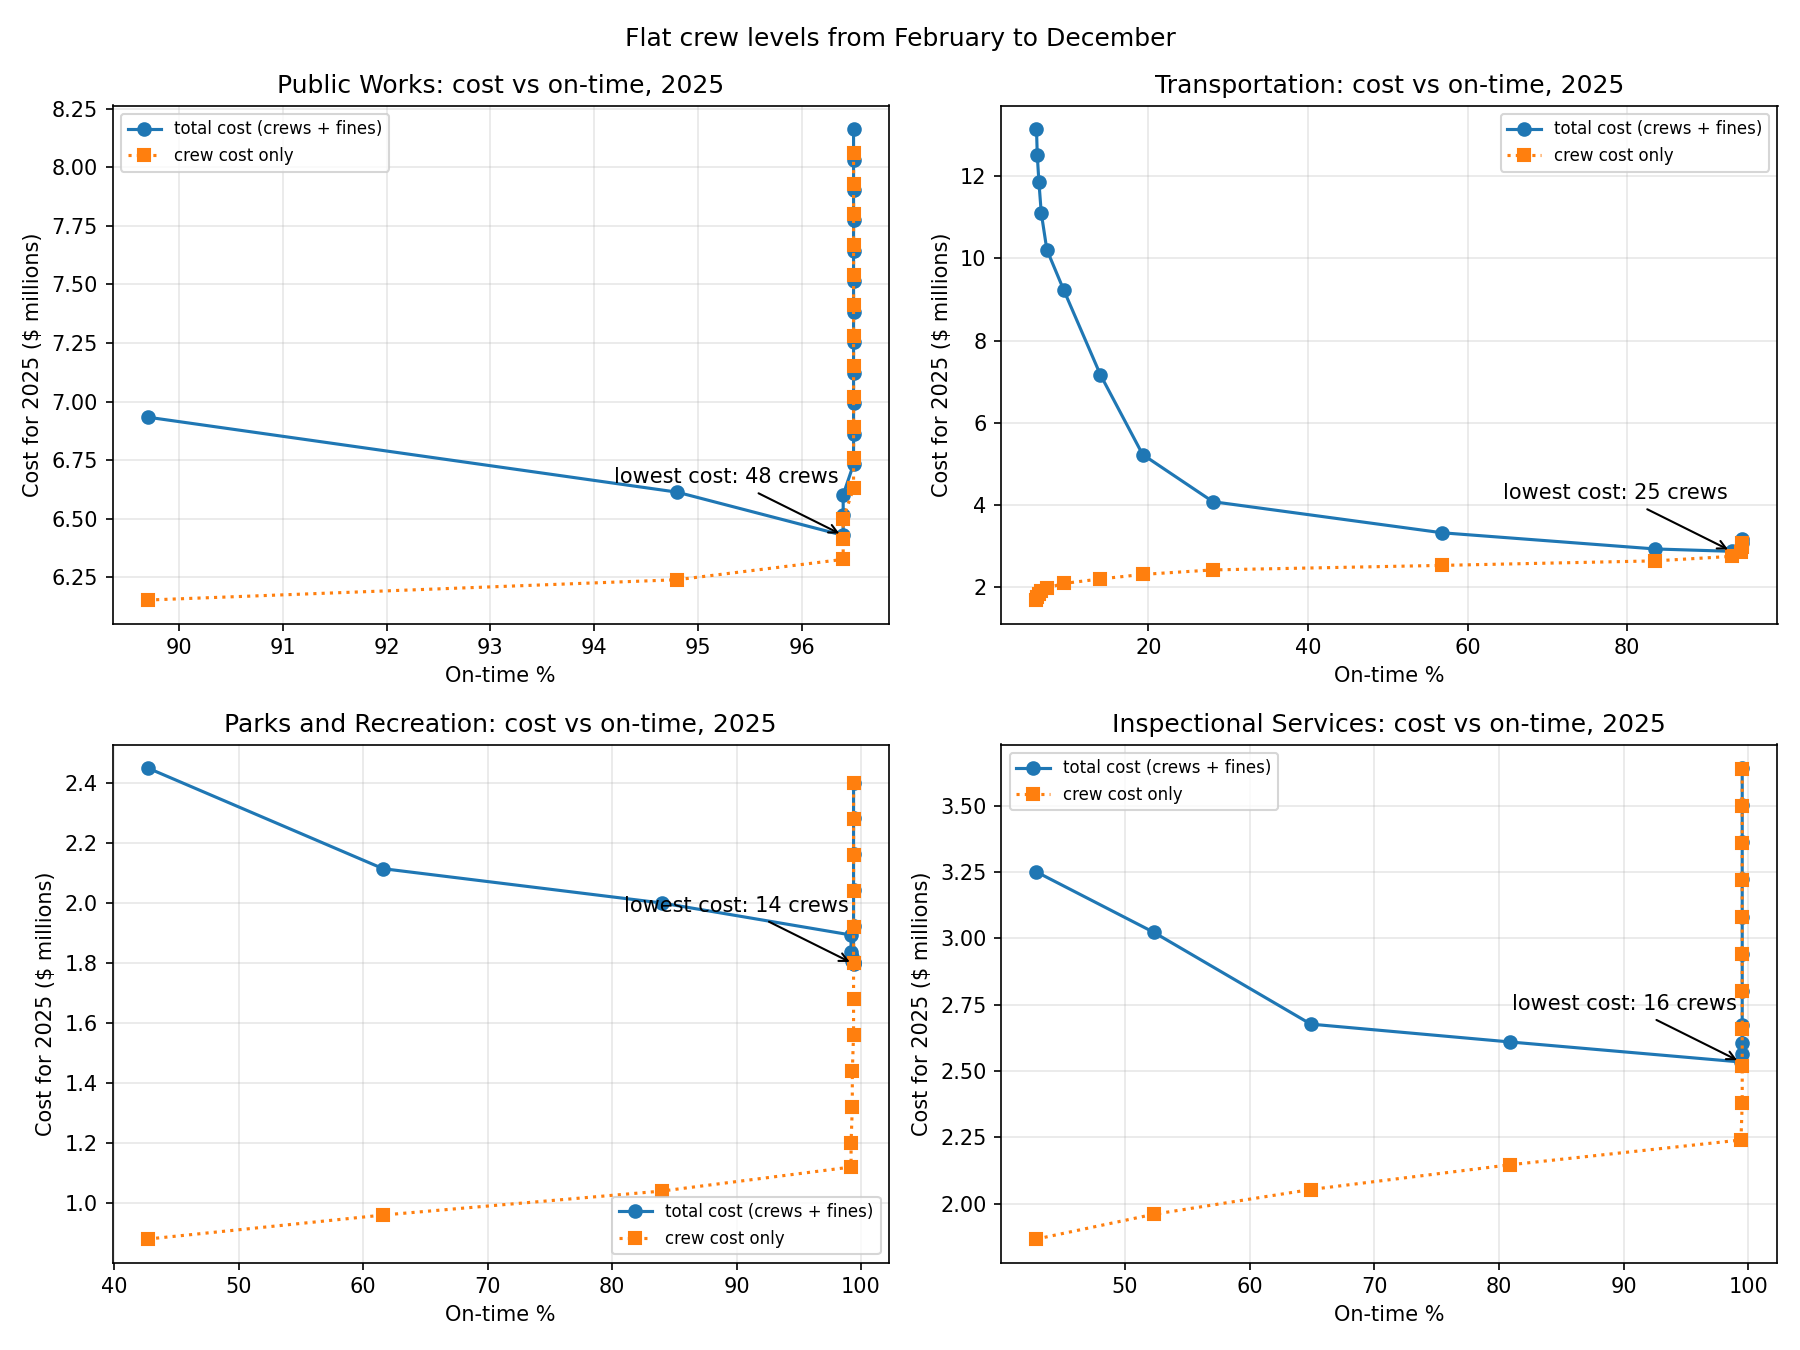

,department,target_pct,on_time_pct,meets_target,total_cost,extra_cost_vs_lowest,avg_crews_feb_dec
0,PWDx,70,96.4,True,6429277,0,48.0
1,PWDx,75,96.4,True,6429277,0,48.0
2,PWDx,80,96.4,True,6429277,0,48.0
3,PWDx,85,96.4,True,6429277,0,48.0
4,PWDx,90,96.4,True,6429277,0,48.0
5,PWDx,95,96.4,True,6429277,0,48.0
6,BTDT,70,93.0,True,2772309,0,24.0
7,BTDT,75,93.0,True,2772309,0,24.0
8,BTDT,80,93.0,True,2772309,0,24.0
9,BTDT,85,93.0,True,2772309,0,24.0


In [25]:
display(Image(str(sensitivity.FIGURE)))
pd.read_csv(sensitivity.TARGETS_FILE)

**Finding [AI-drafted].** Moving left on each chart (fewer crews) makes total cost rise steeply,
because fines grow faster than crew costs fall; moving right beyond the lowest-cost point only adds
idle crews. The lowest-cost plans already beat 90% on time in every department, so on-time targets
up to 90% cost nothing extra. Transportation cannot reach 95% at any cost (its best is about 94%):
crews work weekdays only and many Transportation requests are due the next day, so some weekend
requests are late before anyone can reach them.

## 6. Other Considerations

Both tables below use 2024. On-time % counts every request, as in Section 1. Median days to close
only uses requests that were closed.

### Neighborhoods

Only neighborhoods with at least 100 requests in a department are shown. A few areas appear under
two names in the data (for example "South Boston" and "South Boston / South Boston Waterfront");
these are merged. "Boston" is the city's label when no specific neighborhood was recorded.

In [26]:
nb = equity.neighborhood_table(df)
nb[nb.department.isin(["BTDT", "PWDx"])].sort_values(["department", "on_time_pct"])

,department,neighborhood,requests,on_time_pct,median_days_to_close
0,BTDT,West Roxbury,1678,36.5,4.2
1,BTDT,Jamaica Plain,5566,39.2,3.0
2,BTDT,Hyde Park,2027,39.4,4.3
3,BTDT,Roslindale,2736,42.5,3.0
4,BTDT,Charlestown,3541,42.6,1.5
5,BTDT,Greater Mattapan,2049,44.6,3.5
6,BTDT,Roxbury,5284,45.3,2.0
7,BTDT,East Boston,6328,45.5,1.2
8,BTDT,Mission Hill,1100,47.1,1.1
9,BTDT,South End,4517,47.7,0.9


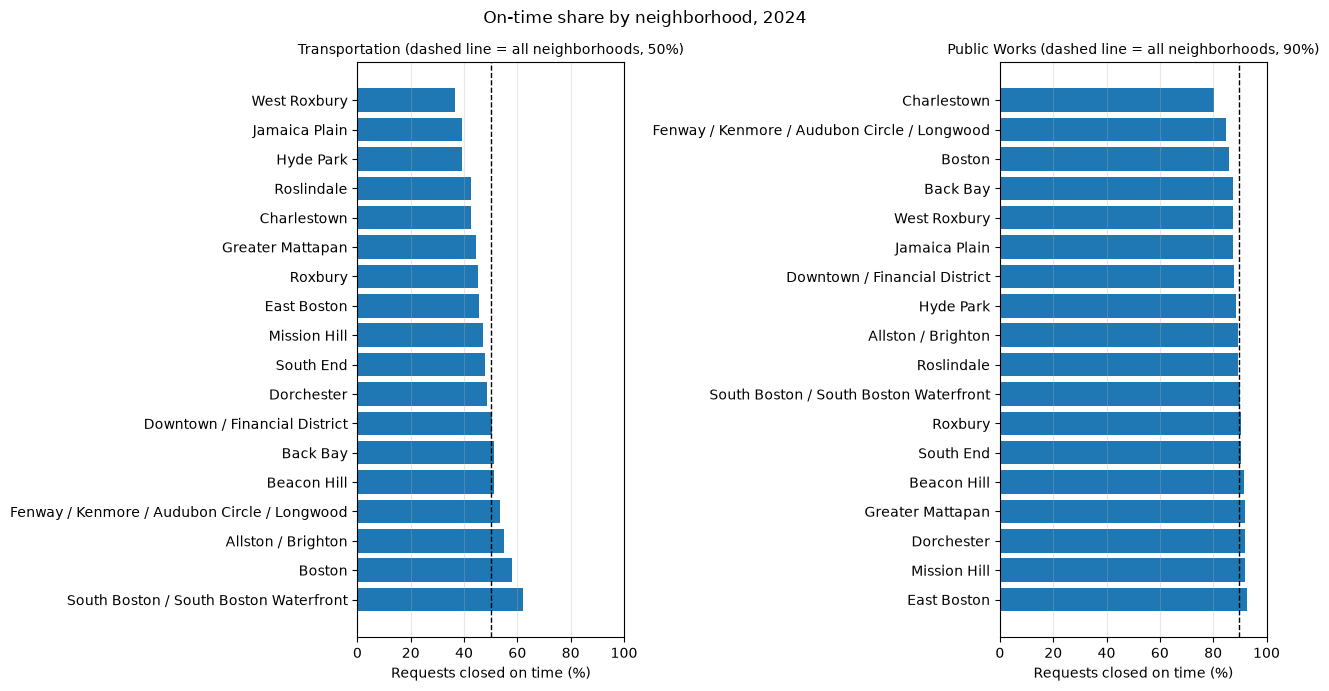

In [27]:
equity.plot_neighborhoods(nb);

**Finding [AI-drafted].** Neighborhoods differ most in Transportation: only 37-39% of requests in
West Roxbury, Jamaica Plain and Hyde Park closed on time, against 62% in South Boston, and residents
there also waited longest (a median of 3-4 days, compared with under a day downtown). Public Works is
more even, between 80% and 93% on time, with Charlestown at the bottom (80%, about 4 points below the
next neighborhood). In Inspectional Services, Greater Mattapan and East Boston are lowest at about 64%.
When Transportation adds crews, the neighborhoods that wait longest should be first in line.

### Employee vs. resident requests

**Employee** = Employee Generated and City Worker App. **Resident** = Citizens Connect App,
Constituent Call and Self Service.

In [28]:
equity.source_group_table(df)

,department,source_group,requests,share_pct,on_time_pct,median_days_to_close
0,BTDT,Employee,50182,61.6,50.1,0.9
1,BTDT,Resident,31265,38.4,49.7,1.6
2,ISD,Employee,7502,40.3,74.7,2.2
3,ISD,Resident,11122,59.7,70.9,3.2
4,PARK,Employee,11307,60.3,95.0,2.8
5,PARK,Resident,7429,39.7,90.4,1.9
6,PWDx,Employee,78174,49.6,89.6,0.1
7,PWDx,Resident,79436,50.4,89.8,0.5


**Finding [AI-drafted].** City employees log 62% of Transportation requests and 60% of Parks
requests themselves, so a large share of crew workload is problems staff spot on their own rather
than resident complaints. Resident requests are closed on time a little less often than employee
requests in Parks (90% vs. 95%) and Inspectional Services (71% vs. 75%). They also take longer to close
everywhere except Parks, where they are faster (median 1.9 vs. 2.8 days). In Public Works the two
on-time rates are equal, but that may hide a gap: 32% of resident requests there have no target date,
and so count as on time, compared with 5% of employee requests.